In [ ]:
%matplotlib inline

# Введение в Машинное обучение с Keras и TensorFlow

Чтобы помочь вам понять основы машинного обучения, в этой демонстрации будут рассмотрены основные этапы создания игрушечной моделей для классификации рукописных чисел с точностью, превышающей 95%.

## Задача для ИИ

Наша цель - построить и обучить нейронную сеть на тысячах изображений рукописных цифр, чтобы она могла успешно идентифицировать любые цифры. Данные, которые будут использованы, - это база данных MNIST, которая содержит 60 000 изображений для обучения и 10 000 тестовых изображений. Мы будем использовать Keras Python API с TensorFlow.

<img src="https://github.com/AviatorMoser/keras-mnist-tutorial/blob/master/mnist.png?raw=1" >

## Импорт нужных библиотек

Во-первых, в среду Python необходимо загрузить некоторые библиотеки.

In [ ]:
import random # для генерации случайных чисел
import numpy as np # Библиотека обработки данных и численных вычислений

from tensorflow.keras.datasets import mnist # Для загрузки набора данных MNIST из Keras

# Библиотеки глубокого обучения (TensorFlow & Keras)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Sequential # Последовательная модель 
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense # Слои модели

from keras.utils import to_categorical # функция работы с категориальными данными

# Библиотека для вывода изображений
import matplotlib.pyplot as plt
import seaborn as sns

ModuleNotFoundError: No module named 'numpy'

## Загружаем тренировочную выборку

Набор данных MNIST удобно доступен в Keras, поэтому мы можем загрузить его напрямую, не скачивая его отдельно. - Набор данных уже разделен на учебный (60 000 изображений) и тестовый (10 000 изображений). - Каждое изображение имеет размер 28×28 пикселей, в оттенках серого и представляет собой рукописные цифры от 0 до 9.

In [7]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

Давайте проверим размерность обучающих и тестовых данных.

In [8]:
print("X_train shape", X_train.shape)
print("y_train shape", y_train.shape)
print("X_test shape", X_test.shape)
print("y_test shape", y_test.shape)

X_train shape (60000, 28, 28)
y_train shape (60000,)
X_test shape (10000, 28, 28)
y_test shape (10000,)


Используя matplotlib, мы можем вывести некоторые образцы изображений из обучающего набора прямо на экран.

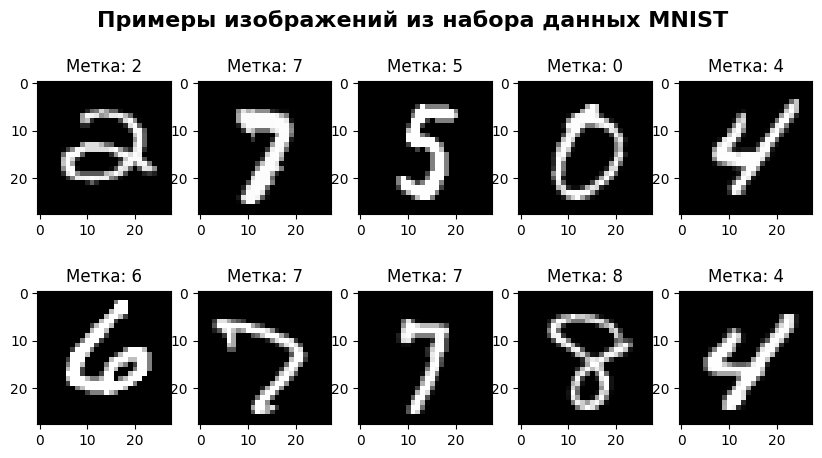

In [42]:
plt.figure(figsize=(10,5))
for i in range(10):
    plt.subplot(2,5,i+1)
    num = random.randint(0, len(X_train))
    plt.imshow(X_train[num], cmap='gray', interpolation='none')
    plt.title("Метка: {}".format(y_train[num]))
plt.suptitle("Примеры изображений из набора данных MNIST", fontsize=16, fontweight='bold')
plt.show()

Давайте рассмотрим одну цифру немного подробнее и распечатаем массив, представляющий эту цифру.

In [10]:
# just a little function for pretty printing a matrix
def matprint(mat, fmt="g"):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
        print("")

# now print!
matprint(X_train[num])

0  0  0  0  0  0  0   0    0    0    0    0    0    0    0    0    0    0    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0    0    0    0    0    0    0    0    0    0    0    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0    0    0    0    0    0    0    0    0    0    0    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0    0    0    0    0    0    0    0    0    0    0    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0    0    0    0    0    0    0    0    0    0    0    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0    0    0   78  254  254  254  255  228   41    0    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0    0  159  245  253  253  253  253  253  241  153    0    0    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0   88  240  253  253  253  253  253  253  253  252  213   11    0    0   0  0  0  0  0  0  
0  0  0  0  0  0  0   0  192  253  253  253  223  253  253  253  253  253  253  

Каждый пиксель представляет собой 8-битное целое число от 0 до 255. 0 - полностью черный, а 255 - полностью белый. Это то, что мы называем одноканальным пикселем. Это называется монохромный.

* Забавный факт! На экране вашего компьютера есть три канала для каждого пикселя: красный, зеленый, синий. Каждый из этих каналов также, вероятно, принимает 8-битное целое число. 3 канала - всего 24 бита - 16 777 216 возможных цветов! *

## Нормализация входных данных

Значения пикселей на изображениях находятся в диапазоне от 0 до 255.

Для лучшего обучения нейронных сетей мы нормализуем эти значения до диапазона от 0 до 1.

Это помогает CNN обучаться более эффективно.

In [11]:
print("До нормализации:")
print("Тренеровочные данные min:", X_train.min(), "max:", X_train.max())
print("Тестовые данные min:", X_test.min(), "max:", X_test.max())

До нормализации:
Тренеровочные данные min: 0 max: 255
Тестовые данные min: 0 max: 255


In [12]:
# Преобразовать значения пикселей из целых чисел (0-255) в числа с плавающей точкой (0-1)
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("После нормализации:")
print("Тренеровочные данные min:", X_train.min(), "max:", X_train.max())
print("Тестовые данные min:", X_test.min(), "max:", X_test.max())

После нормализации:
Тренеровочные данные min: 0.0 max: 1.0
Тестовые данные min: 0.0 max: 1.0


В настоящее время изображения имеют форму (28, 28).

Для входных данных CNN необходимо добавить измерение канала (поскольку изображения представлены в оттенках серого).

Забавный факт! Добавление измерения необходимо в картинки, чтобы их можно было правильно использовать сверточными слоями в модели.

Окончательная форма: (28, 28, 1).

In [13]:
# Reshape training and testing images
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training data shape after reshape:", X_train.shape)
print("Testing data shape after reshape:", X_test.shape)

Training data shape after reshape: (60000, 28, 28, 1)
Testing data shape after reshape: (10000, 28, 28, 1)


Затем мы изменим наши классы (уникальные цифры) так, чтобы они соответствовали формату one-hot, т.е.

```
0 -> [1, 0, 0, 0, 0, 0, 0, 0, 0]
1 -> [0, 1, 0, 0, 0, 0, 0, 0, 0]
2 -> [0, 0, 1, 0, 0, 0, 0, 0, 0]
etc.
```

Если конечный результат нашей сети очень близок к одному из этих классов, то, скорее всего, это именно этот класс. Например, если конечный результат:

```
[0, 0.94, 0, 0, 0, 0, 0.06, 0, 0]
```
то наиболее вероятно, что это изображение цифры `1`.

Убедимся, что набор данных содержит цифры от 0 до 9 (10 классов).

In [14]:
unique_classes = np.unique(y_train)
number_classes = len(unique_classes) # количество уникальных цифр
print("Unique labels:", unique_classes)
print("Number of labels:", number_classes)

Unique labels: [0 1 2 3 4 5 6 7 8 9]
Number of labels: 10


In [15]:
Y_train = to_categorical(y_train, number_classes)
Y_test = to_categorical(y_test, number_classes)

Таперь наш датасет готов к использованию для обучения модели CNN.

# Создание модели НС

Мы построим сверточную нейронную сеть (CNN) для классификации рукописных цифр (0–9).
Архитектура:
1. Conv2D слой + функция активации ReLU  → извлечение признаков изображения.
2. MaxPooling2D слой → уменьшение разрешения карт признаков.
3. Dropout →  отсев некоторых нейронов для предотвращение переобучения.
4. Flatten слой → преобразование двумерных признаков в одномерные (сглаживание).
5. Dense слой → полносвязные слои для классификации.
6. Выходной слой (Dense + функция активации Softmax) → распределение вероятностей по 10 классам.

In [16]:
# Sequential (последовательная) модель представляет собой линейный набор слоев. Слои идут друг за другом
model = Sequential([
    # Первый слой: Conv + Pool block
    Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.25),

    # Второй слой: Conv + Pool block
    Conv2D(64, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Dropout(0.25),

    # Третий слой: Flatten + Dense layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Выходной слой (10 classes for digits 0–9)
    Dense(10, activation='softmax')
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Подведем итог построенной модели

In [17]:
# Print model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## Компиляция модели

При компиляции модели Keras просит вас указать **функцию потерь** и **оптимизатор**. Функция потерь, которую мы здесь будем использовать, называется *категориальной кросс-энтропией* и является функцией потерь, хорошо подходящей для сравнения двух распределений вероятностей.

Наши прогнозы представляют собой распределения вероятностей по десяти различным цифрам (например, «мы на 80% уверены, что изображена 3, на 10% уверены, что это 8, 5% - это 2, и т. д.»), А цель - это распределение вероятностей. со 100% для правильной категории и 0 для всего остального. Перекрестная энтропия - это мера того, насколько ваше предсказанное распределение отличается от целевого распределения. [Подробнее в Википедии] (https://en.wikipedia.org/wiki/Cross_entropy)

Оптимизатор помогает определить, насколько быстро модель обучается с помощью **градиентного спуска**. Скорость спуска по градиенту называется **скоростью обучения**.

In [18]:
# Давайте используем оптимизатор Adam для обучения.
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

## Обучите модель!
Это самое интересное!

Теперь обучим нашу модель CNN на обучающих данных MNIST.

- Мы будем использовать функцию fit() Keras.
- Для контроля эффективности на ранее не просмотренных данных во время обучения будет использоваться тестовую выборку (10%).
- История обучения (потери и точность) будет сохранена для визуализации на следующем этапе.

Используемые параметры:
- Эпохи: 10 (можно настроить)
- batch_size: 128 (стандартный выбор для повышения эффективности)

Размер пакета (batch_size) определяет, сколько данных на шаг используется для вычисления функции потерь, градиентов и обратного распространения. Большие размеры пакетов позволяют сети быстрее завершить обучение; Однако есть и другие факторы, помимо скорости тренировки, которые следует учитывать.

Например:

- Слишком большой размер батча сглаживает локальные минимумы функции потерь, заставляя оптимизатор выбирать один, потому что он считает, что нашел глобальный минимум.

- Слишком маленький размер батча создает очень шумную функцию потерь, и оптимизатор может никогда не найти глобальный минимум.

Таким образом, чтобы найти подходящий размер батча, может потребоваться метод проб и ошибок!

In [19]:
EPOCHS = 10
BATCH_SIZE = 128

history = model.fit(
    X_train, Y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_split=0.1,
    verbose=1
)

# Check what metrics are stored in history
print("History keys:", history.history.keys())

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.7567 - loss: 0.7587 - val_accuracy: 0.9793 - val_loss: 0.0683
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9600 - loss: 0.1344 - val_accuracy: 0.9855 - val_loss: 0.0523
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9708 - loss: 0.0957 - val_accuracy: 0.9890 - val_loss: 0.0390
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9745 - loss: 0.0837 - val_accuracy: 0.9898 - val_loss: 0.0372
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9792 - loss: 0.0648 - val_accuracy: 0.9888 - val_loss: 0.0345
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9805 - loss: 0.0633 - val_accuracy: 0.9907 - val_loss: 0.0353
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9837 - loss: 0.0541 - val_accuracy: 0.9895 - val_loss: 0.0339
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9835 - loss: 0.0526 - val_accuracy: 

Два числа, расположенные по порядку, представляют значение функции потерь сети на обучающем наборе и общую точность сети на обучающих данных.

Но как он работает с данными, на которых он не тренировался?

Построим график точность обучения

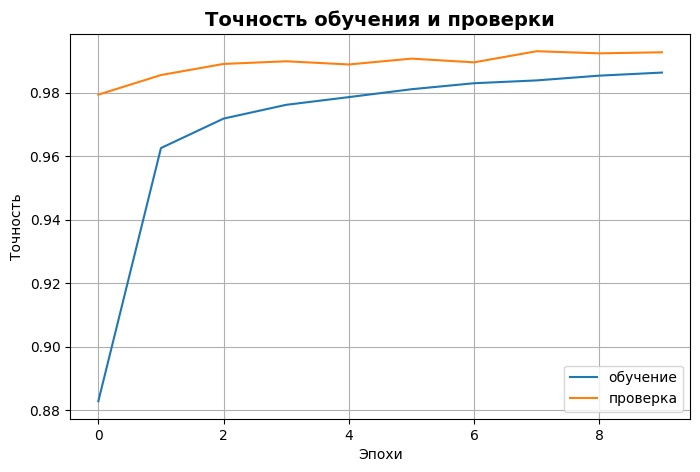

In [51]:
# Plot training vs validation accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='обучение')
plt.plot(history.history['val_accuracy'], label='проверка')
plt.title("Точность обучения и проверки", fontsize=14, fontweight="bold")
plt.xlabel("Эпохи")
plt.ylabel("Точность")
plt.legend()
plt.grid(True)
plt.show()

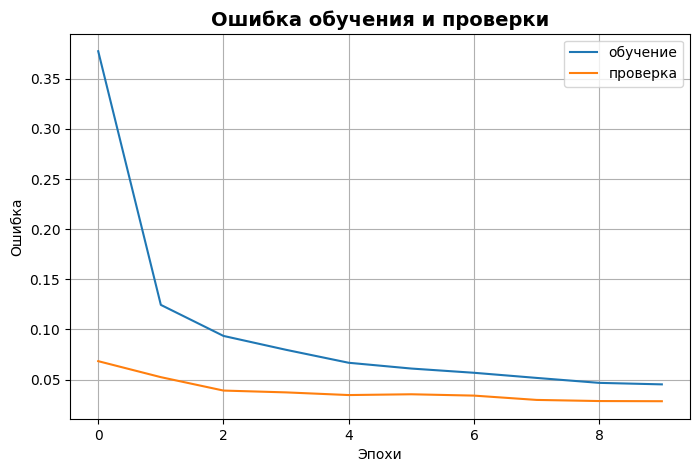

In [50]:
# Plot training vs validation loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='обучение')
plt.plot(history.history['val_loss'], label='проверка')
plt.title("Ошибка обучения и проверки", fontsize=14, fontweight="bold")
plt.xlabel("Эпохи")
plt.ylabel("Ошибка")
plt.legend()
plt.grid(True)
plt.show()

## Оценка точность модели на тестовых данных

In [29]:
test_loss, test_accuracy = model.evaluate(X_test, Y_test, verbose=0)

print(f"Точность на тестовых данных: {test_accuracy:.4f}")
print(f"Ошибка на тестовых данных: {test_loss:.4f}")

Точность на тестовых данных: 0.9921
Ошибка на тестовых данных: 0.0248


### Проверка вывода

Всегда полезно проверить результат и убедиться, что все выглядит нормально. Здесь мы рассмотрим несколько примеров, когда всё правильно, и несколько примеров, когда он ошибается.

In [34]:
# The predict_classes function outputs the highest probability class
# according to the trained classifier for each input example.
# predicted_classes = model.predict_classes(X_test)
predict_x = model.predict(X_test)
predicted_classes = np.argmax(predict_x,axis=1)

# Check which items we got right / wrong
correct_indices = np.nonzero(predicted_classes == np.argmax(Y_test, axis=1))[0]

incorrect_indices = np.nonzero(predicted_classes != np.argmax(Y_test, axis=1))[0]

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


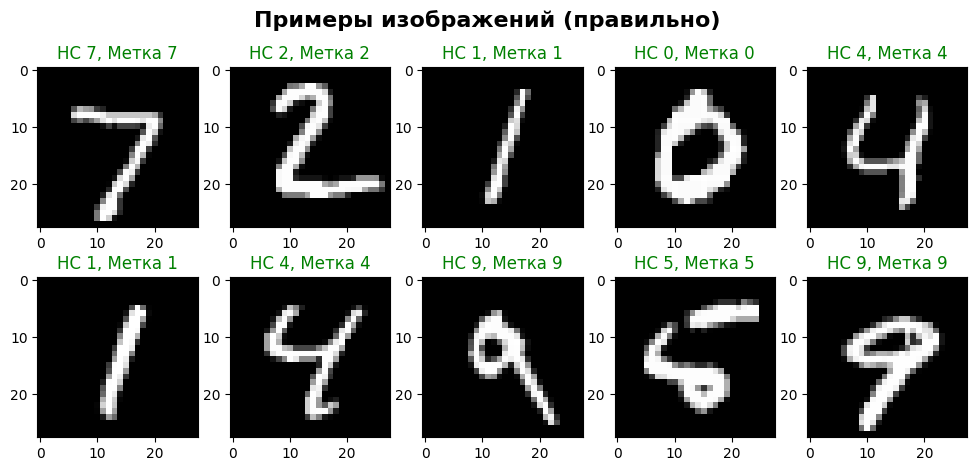

In [54]:
plt.figure(figsize=(12,5))
for i, correct in enumerate(correct_indices[:10]):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[correct].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("НС {}, Метка {}".format(predicted_classes[correct], np.argmax(Y_test[correct])), fontsize=12, color='green')

plt.suptitle("Примеры изображений (правильно)", fontsize=16, fontweight='bold')
plt.show()

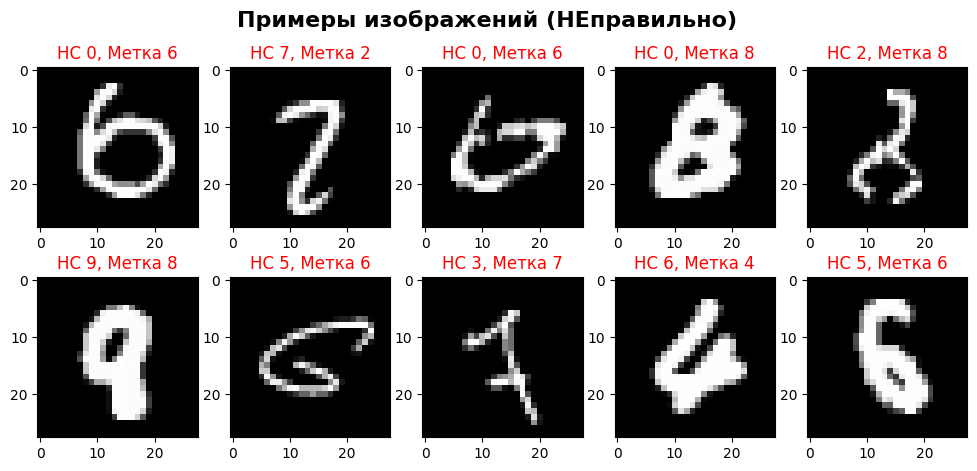

In [55]:
plt.figure(figsize=(12,5))
for i, incorrect in enumerate(incorrect_indices[:10]):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[incorrect].reshape(28,28), cmap='gray', interpolation='none')
    plt.title("НС {}, Метка {}".format(predicted_classes[incorrect], np.argmax(Y_test[incorrect])), fontsize=12, color='red')

plt.suptitle("Примеры изображений (НЕправильно)", fontsize=16, fontweight='bold')
plt.show()

# Сохранение модели

In [62]:
model.save("mnist_cnn_model.keras", overwrite=True)

print("Модель успешно сохранена как 'mnist_cnn_model.keras'")

Модель успешно сохранена как 'mnist_cnn_model.keras'
